In [9]:
%pip install "tensorflow[cuda]" mlflow pandas azure-storage-blob matplotlib opencv-python scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [10]:
import os
import sys
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("Num GPUs Available:", len(gpus))
if gpus:
    for gpu in gpus:
        print("  ->", gpu)
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("Memory growth setting:", e)
else:
    print("WARNING: No GPU detected! Check nvidia-smi and restart kernel.")


Num GPUs Available: 1
  -> PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Memory growth setting: Physical devices cannot be modified after being initialized


In [11]:
import os
from azure.storage.blob import BlobServiceClient

# set AZURE_STORAGE_CONNECTION_STRING in the environment first
service = BlobServiceClient.from_connection_string(os.environ["AZURE_STORAGE_CONNECTION_STRING"])
container = service.get_container_client("kcrowly-vast")


In [12]:
# Download dataset from Azure Blob Storage if not already present locally
import os
import tarfile

data_archive = "neurovision_data.tar.gz"
data_dir = "Data/raw" if os.path.exists("Data/raw") else ("../Data/raw" if os.path.exists("../Data/raw") else "Data/raw")

if not os.path.exists(data_dir):
    print("Data folder not found locally. Downloading from Azure Blob Storage...")
    with open(data_archive, "wb") as f:
        download_stream = container.download_blob("data/neurovision_data.tar.gz")
        f.write(download_stream.readall())
    print("Download complete. Extracting dataset and helpers...")
    with tarfile.open(data_archive, "r:gz") as tar:
        tar.extractall(".")
    data_dir = "Data/raw" if os.path.exists("Data/raw") else "../Data/raw"
    print(f"Dataset ready at: {data_dir}")
else:
    print(f"Dataset already available at: {data_dir}")


Dataset already available at: Data/raw


Total MRI images: 7023 | Classes: ('glioma', 'meningioma', 'notumor', 'pituitary')


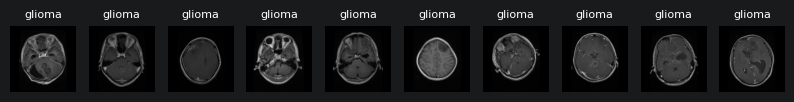

In [13]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Add src to path to import neurovision.data helper functions
sys.path.insert(0, os.path.abspath("src"))
sys.path.insert(0, os.path.abspath("../src"))
sys.path.insert(0, os.path.abspath("."))

from neurovision import data

paths, labels, _ = data.list_image_files(data_dir)
print(f"Total MRI images: {len(paths)} | Classes: {data.CLASSES}")

# Preview sample MRI scans
plt.figure(figsize=(10, 2))
for i in range(min(10, len(paths))):
    plt.subplot(1, 10, i + 1)
    img = cv2.cvtColor(data.load_image(paths[i]), cv2.COLOR_BGR2RGB)
    plt.imshow(img)
    plt.title(data.CLASSES[labels[i]], fontsize=8)
    plt.axis("off")
plt.show()


MobileNet v2 PreProc

In [14]:
import tensorflow as tf

BATCH_SIZE = 32
IMG_SIZE = (224, 224)

# Create MRI-specific augmentation using data.py helper
augmentation = data.make_augmentation(rotation=0.03, zoom=0.1, translation=0.1, seed=42)

# Build train, validation and test datasets with MobileNetV2 preprocessing ([-1, 1])
datasets = data.make_datasets(
    data_dir,
    size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    val_split=0.15,
    test_split=0.15,
    seed=42,
    augmentation=augmentation,
    preprocess="mobilenet"
)

# Format targets to one-hot encoding for categorical_crossentropy
train_ds = datasets["train"].map(lambda x, y: (x, tf.one_hot(y, data.NUM_CLASSES)),
                                num_parallel_calls=tf.data.AUTOTUNE)
test_ds = datasets["test"].map(lambda x, y: (x, tf.one_hot(y, data.NUM_CLASSES)),
                               num_parallel_calls=tf.data.AUTOTUNE)

print("Datasets successfully prepared with data.py!")


Datasets successfully prepared with data.py!


In [15]:
from tensorflow.keras.applications import MobileNetV2
base_model = MobileNetV2(weights="imagenet",
                        include_top=False,
                        input_shape=(224, 224, 3))
base_model.trainable = False


In [16]:
from tensorflow.keras import layers, models

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(data.NUM_CLASSES, activation="softmax")  # 4 classes for Brain Tumor
])
model.compile(optimizer="adam",
             loss="categorical_crossentropy",
             metrics=["accuracy"])
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
checkpoint = ModelCheckpoint("mobilenetv2_neurovision.keras", save_best_only=True)

history = model.fit(train_ds, validation_data=test_ds, epochs=10,
                   callbacks=[early_stop, checkpoint])


Epoch 1/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 28s 108ms/step - accuracy: 0.6582 - loss: 0.8864 - val_accuracy: 0.7865 - val_loss: 0.5377
Epoch 2/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - accuracy: 0.8383 - loss: 0.4301 - val_accuracy: 0.8520 - val_loss: 0.4000
Epoch 3/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 12s 77ms/step - accuracy: 0.8639 - loss: 0.3636 - val_accuracy: 0.8083 - val_loss: 0.5473
Epoch 4/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 12s 74ms/step - accuracy: 0.8728 - loss: 0.3251 - val_accuracy: 0.8567 - val_loss: 0.3952
Epoch 5/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.8798 - loss: 0.2927 - val_accuracy: 0.8378 - val_loss: 0.4385
Epoch 6/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 12s 75ms/step - accuracy: 0.9007 - loss: 0.2658 - val_accuracy: 0.8710 - val_loss: 0.3442
Epoch 7/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.9060 - loss: 0.2479 - val_accuracy: 0.8539 - val_loss: 0.3983
Epoch 8/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 12s 76ms/step - accuracy: 0.9083 - loss: 0.2467 -

In [18]:
with open("mobilenetv2_neurovision.keras", "rb") as f:
    container.upload_blob("models/mobilenetv2_neurovision.keras", f, overwrite=True)
print("Uploaded mobilenetv2_neurovision.keras to Azure Blob Storage!")


Uploaded mobilenetv2_neurovision.keras to Azure Blob Storage!


In [19]:
import subprocess, time

subprocess.run(["pkill", "-f", "mlflow"])
time.sleep(3)

p = subprocess.Popen(
    ["mlflow", "server", "--host", "0.0.0.0", "--port", "5000",
     "--disable-security-middleware"],
    stdout=open("mlflow.log", "w"), stderr=subprocess.STDOUT,
)
time.sleep(15)

print("exit code:", p.poll())
print(open("mlflow.log").read()[-1500:])


exit code: None
/models/signature.py", line 23, in <module>
    from mlflow.models.utils import _contains_params, _Example
  File "/venv/main/lib/python3.10/site-packages/mlflow/models/utils.py", line 51, in <module>
    from scipy.sparse import csc_matrix, csr_matrix
  File "/venv/main/lib/python3.10/site-packages/scipy/sparse/__init__.py", line 315, in <module>
    from . import csgraph
  File "/venv/main/lib/python3.10/site-packages/scipy/sparse/csgraph/__init__.py", line 187, in <module>
    from ._laplacian import laplacian
  File "/venv/main/lib/python3.10/site-packages/scipy/sparse/csgraph/_laplacian.py", line 7, in <module>
    from scipy.sparse.linalg import LinearOperator
  File "/venv/main/lib/python3.10/site-packages/scipy/sparse/linalg/__init__.py", line 131, in <module>
    from ._isolve import *
  File "/venv/main/lib/python3.10/site-packages/scipy/sparse/linalg/_isolve/__init__.py", line 4, in <module>
    from .iterative import *
  File "/venv/main/lib/python3.10/site-

In [20]:
import os
print(os.path.abspath("mobilenetv2_neurovision.keras"))


/mobilenetv2_neurovision.keras


## Fine Tuning

In [22]:
loss, acc = model.evaluate(test_ds)
print(f"Test Accuracy: {acc:.2f}")


33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8871 - loss: 0.2767
Test Accuracy: 0.89


In [23]:
base_model.trainable = True

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss="categorical_crossentropy",
              metrics=["accuracy"])


In [24]:
fine_tune_epochs = 10
total_epochs = 10 + fine_tune_epochs

history_fine = model.fit(train_ds,
                         epochs=total_epochs,
                         initial_epoch=10,
                         validation_data=test_ds)


Epoch 11/20
152/154 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7086 - loss: 0.8808

2026-10-22 13:06:33.115794: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_14435', 12 bytes spill stores, 12 bytes spill loads



154/154 ━━━━━━━━━━━━━━━━━━━━ 72s 216ms/step - accuracy: 0.7099 - loss: 0.8767 - val_accuracy: 0.8871 - val_loss: 0.2911
Epoch 12/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 13s 84ms/step - accuracy: 0.8451 - loss: 0.4182 - val_accuracy: 0.8843 - val_loss: 0.3124
Epoch 13/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 12s 78ms/step - accuracy: 0.8711 - loss: 0.3329 - val_accuracy: 0.8719 - val_loss: 0.3290
Epoch 14/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 14s 93ms/step - accuracy: 0.8967 - loss: 0.2814 - val_accuracy: 0.8833 - val_loss: 0.3010
Epoch 15/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 14s 87ms/step - accuracy: 0.9107 - loss: 0.2374 - val_accuracy: 0.8928 - val_loss: 0.3027
Epoch 16/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 14s 87ms/step - accuracy: 0.9138 - loss: 0.2282 - val_accuracy: 0.8880 - val_loss: 0.3002
Epoch 17/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 14s 88ms/step - accuracy: 0.9345 - loss: 0.1973 - val_accuracy: 0.8937 - val_loss: 0.2834
Epoch 18/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 14s 89ms/step - accuracy: 0.9438 - loss: 0.1637 - val

## Evaluation :


In [25]:
loss, acc = model.evaluate(test_ds)
print(f"Test Accuracy: {acc:.2f}")


33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9087 - loss: 0.2563
Test Accuracy: 0.90


In [26]:
# Save and upload the final fine-tuned model to Azure Blob Storage
finetuned_model_path = "mobilenetv2_neurovision_finetuned.keras"
model.save(finetuned_model_path)

with open(finetuned_model_path, "rb") as f:
    container.upload_blob(f"models/{finetuned_model_path}", f, overwrite=True)
print(f"Successfully uploaded {finetuned_model_path} to Azure Blob Storage!")


Successfully uploaded mobilenetv2_neurovision_finetuned.keras to Azure Blob Storage!
